In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [13]:

# Load the Iris dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add target labels
df["species"] = iris.target
df["species_name"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

# Display the first five rows
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [14]:

# Check the dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display descriptive statistics
print("\nDescriptive Statistics:")
df.describe()


Dataset Shape: (150, 6)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species', 'species_name']

Data Types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
species_name             str
dtype: object

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


Number of flowers in each species:
species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


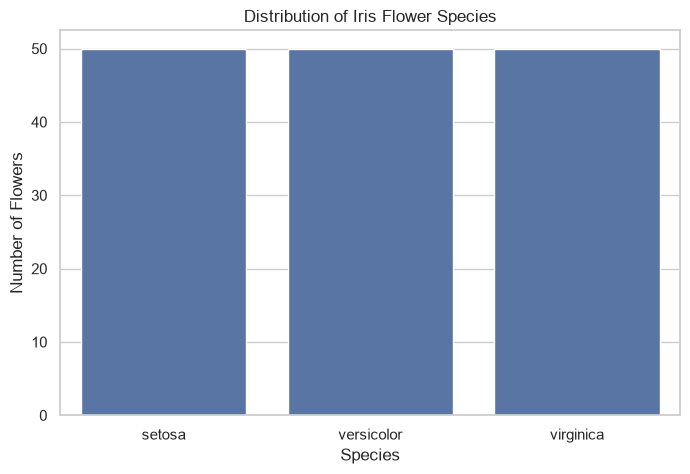

In [15]:

# Count the number of flowers in each species
species_counts = df["species_name"].value_counts()

print("Number of flowers in each species:")
print(species_counts)

# Visualize species distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species_name")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.show()


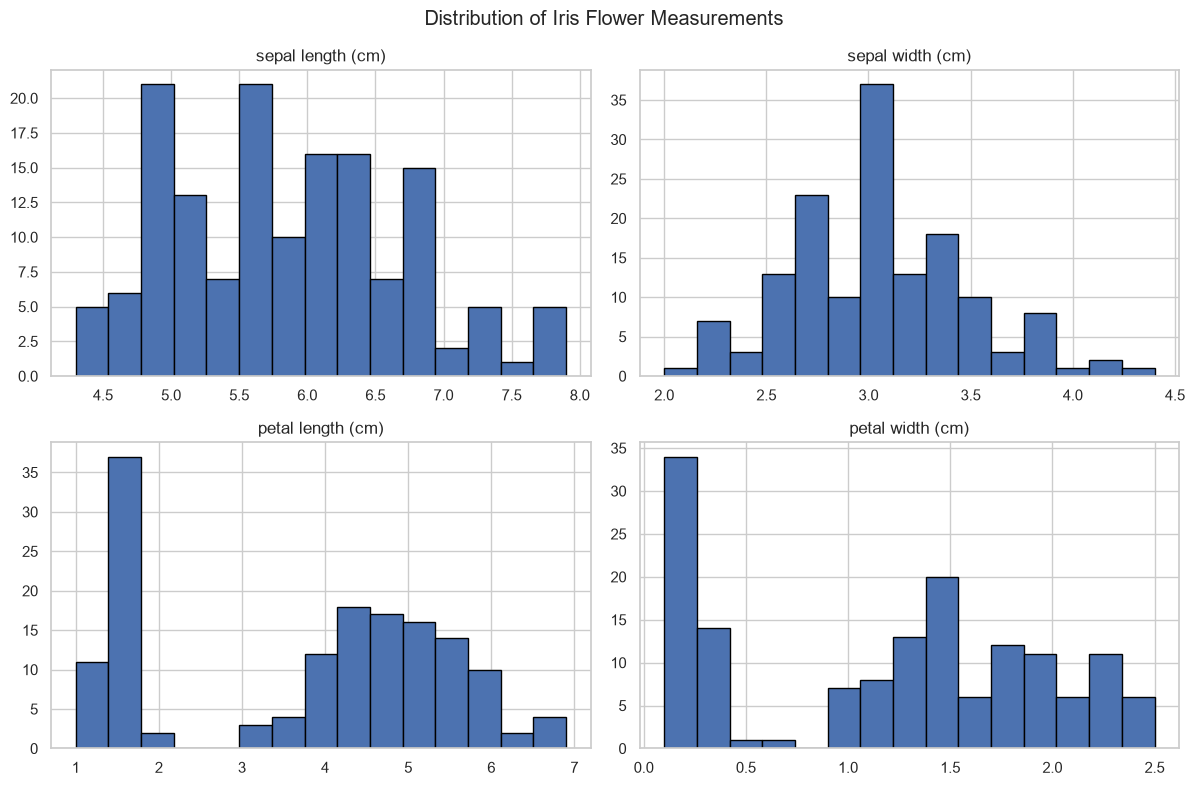

In [16]:

# Plot the distribution of all four flower measurements
features = iris.feature_names

df[features].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Flower Measurements")
plt.tight_layout()
plt.show()


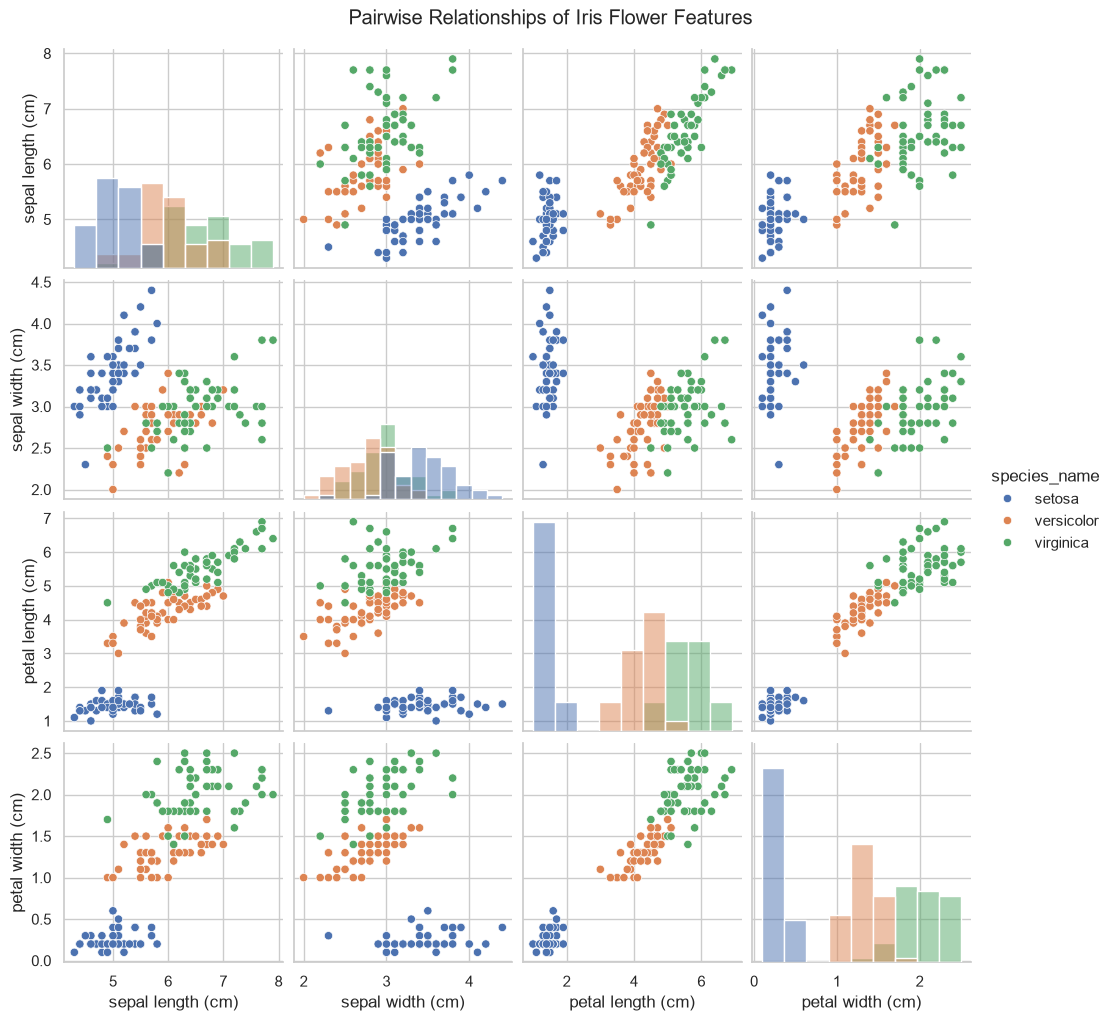

In [17]:

# Visualize relationships between features by species
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species_name",
    diag_kind="hist"
)

plt.suptitle(
    "Pairwise Relationships of Iris Flower Features",
    y=1.02
)

plt.show()


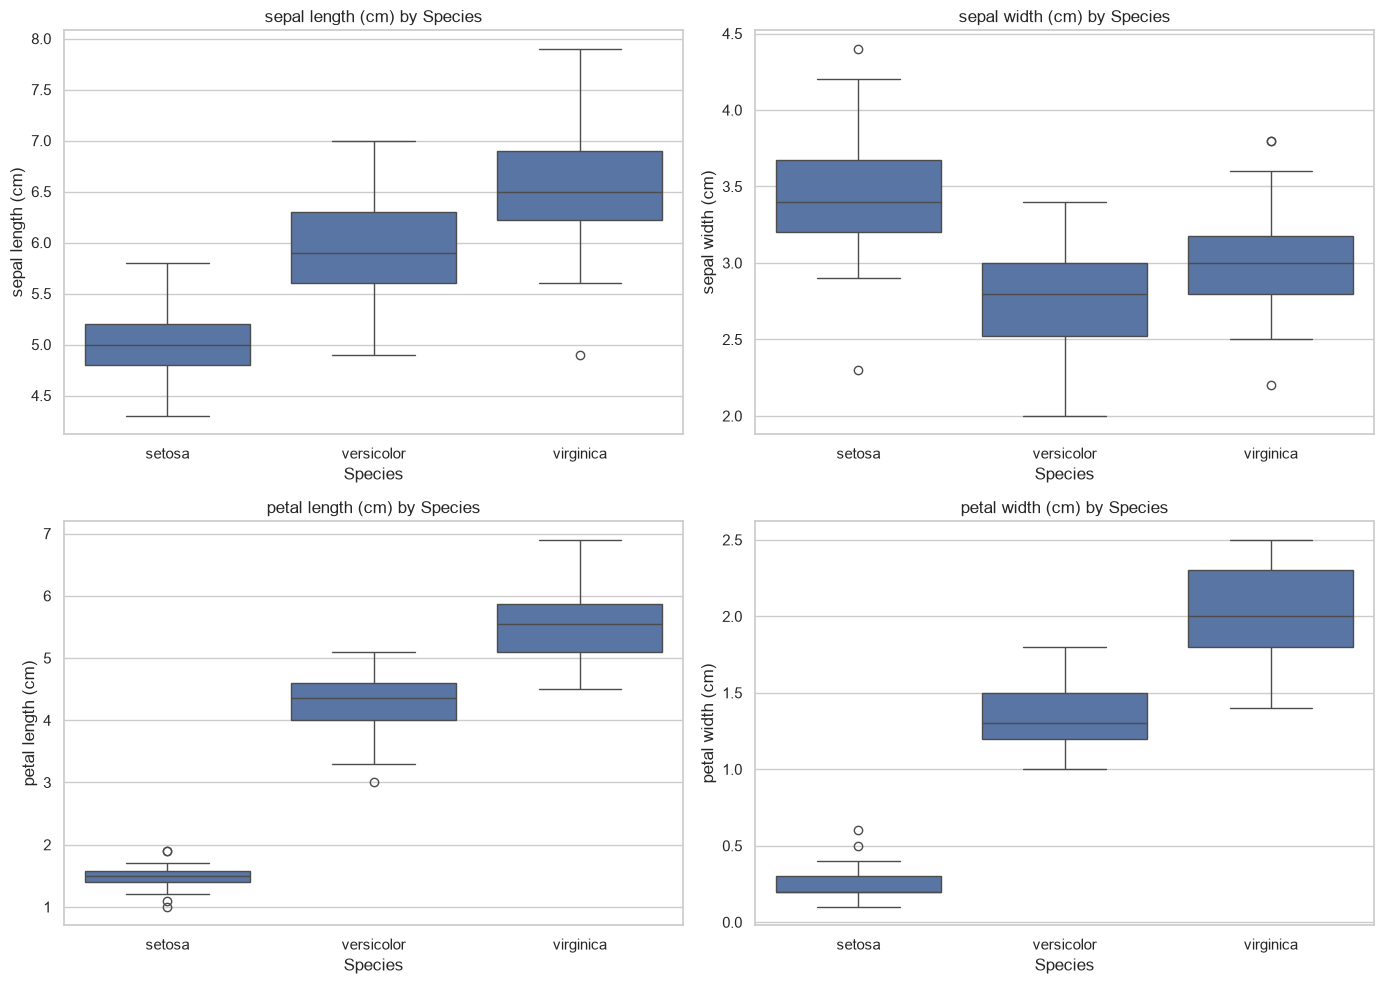

In [18]:

# Visualize feature distributions for each species
plt.figure(figsize=(14, 10))

for i, feature in enumerate(iris.feature_names, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, x="species_name", y=feature)
    plt.title(f"{feature} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()


### Exploratory Data Analysis — Key Findings

- The dataset contains three Iris species with 50 samples per species.
- The pairplot helps compare the relationships between all four flower measurements.
- Petal length and petal width appear particularly useful for distinguishing the species.
- Setosa is generally easier to separate, while Versicolor and Virginica can overlap in some measurements.
- Boxplots help compare the distributions and spread of each measurement across species.

**Note:** These are initial visual observations. Model evaluation will help assess how effectively the selected features classify the species.

### 4. Feature Selection Discussion

The Iris dataset contains four input features: sepal length, sepal width, petal length, and petal width.

- **Petal Length:** Helps distinguish the three Iris species.
- **Petal Width:** Is also highly useful for separating the species.
- **Sepal Length:** Provides useful information but may show overlap between species.
- **Sepal Width:** May be less effective on its own because the species can have overlapping values.

Overall, petal length and petal width are expected to be particularly discriminative features. These observations can be verified using the pairplot and box plots.

All four features will initially be used to train the classification models.

In [19]:

# Separate input features and target variable
X = df[iris.feature_names]
y = df["species"]

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (120, 4)
Testing features shape: (30, 4)
Training target shape: (120,)
Testing target shape: (30,)


In [20]:

# Create the Logistic Regression model
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [21]:

# Create the KNN model
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")


KNN model trained successfully!


In [22]:

# Create the Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [23]:

# Create the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [24]:

# Generate predictions using all trained models
y_pred_logistic = logistic_model.predict(X_test)
y_pred_knn = knn_model.predict(X_test)
y_pred_decision_tree = decision_tree_model.predict(X_test)
y_pred_random_forest = random_forest_model.predict(X_test)

print("Predictions generated successfully for all models!")


Predictions generated successfully for all models!


Model Accuracy Comparison:


,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.933333,93.33
1,KNN,0.933333,93.33
2,Decision Tree,0.933333,93.33
3,Random Forest,0.900000,90.00


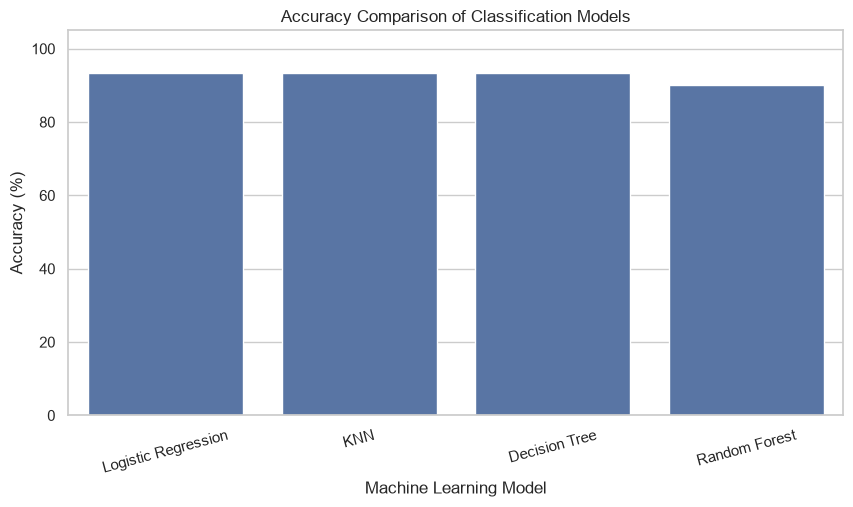

In [25]:

# Calculate accuracy for each model
model_accuracies = {
    "Logistic Regression": accuracy_score(y_test, y_pred_logistic),
    "KNN": accuracy_score(y_test, y_pred_knn),
    "Decision Tree": accuracy_score(y_test, y_pred_decision_tree),
    "Random Forest": accuracy_score(y_test, y_pred_random_forest)
}

# Create a comparison DataFrame
accuracy_df = pd.DataFrame(
    list(model_accuracies.items()),
    columns=["Model", "Accuracy"]
)

accuracy_df["Accuracy (%)"] = (
    accuracy_df["Accuracy"] * 100
).round(2)

accuracy_df = accuracy_df.sort_values(
    by="Accuracy",
    ascending=False
)

print("Model Accuracy Comparison:")
display(accuracy_df)

# Visualize model accuracy
plt.figure(figsize=(10, 5))
sns.barplot(
    data=accuracy_df,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.show()


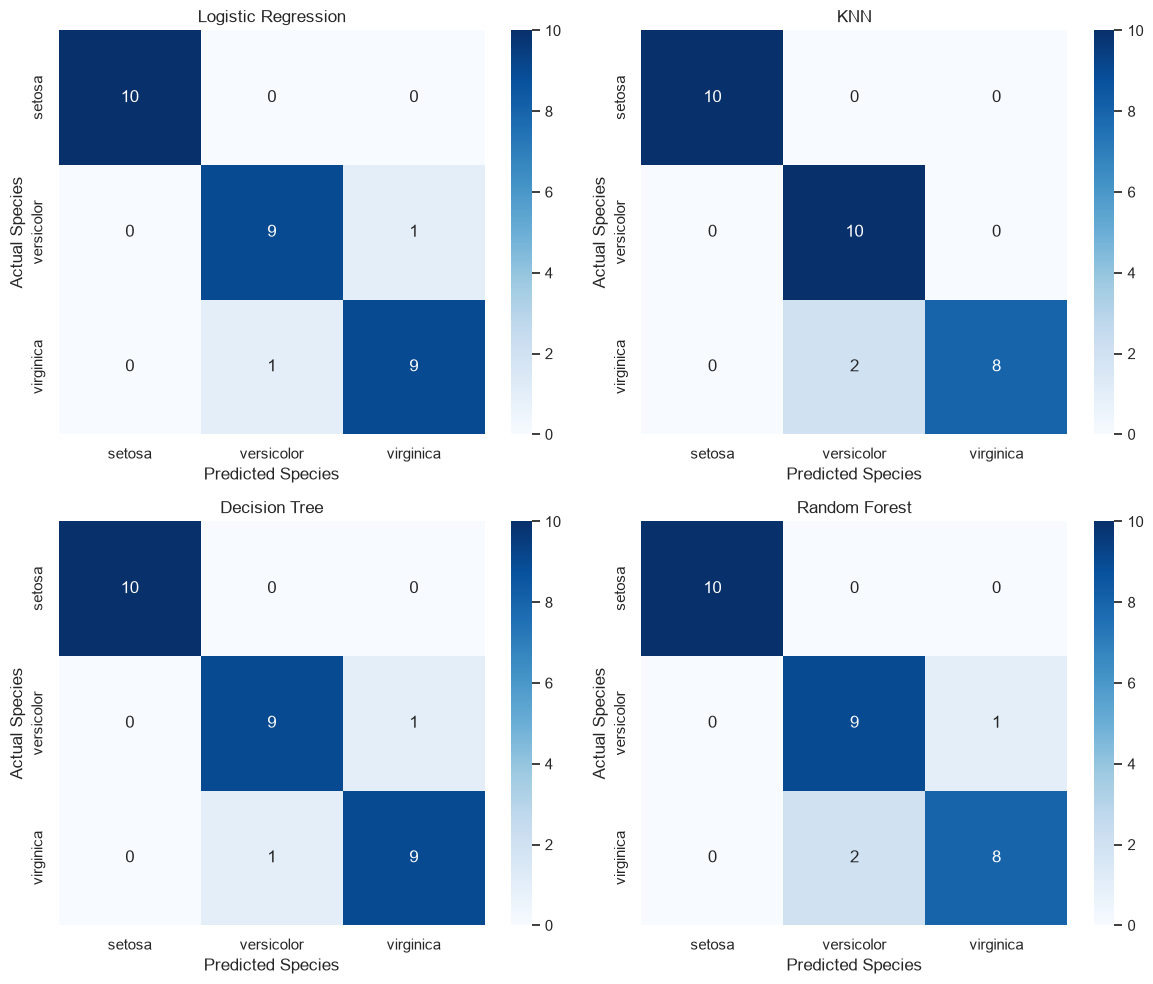

In [26]:

# Store model predictions
predictions = {
    "Logistic Regression": y_pred_logistic,
    "KNN": y_pred_knn,
    "Decision Tree": y_pred_decision_tree,
    "Random Forest": y_pred_random_forest
}

# Plot confusion matrices for all models
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, y_pred) in zip(axes.flat, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()


In [27]:

# Generate classification reports for all models
for model_name, y_pred in predictions.items():
    print(f"\n{'=' * 55}")
    print(f"Classification Report: {model_name}")
    print('=' * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=iris.target_names,
            zero_division=0
        )
    )



Classification Report: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Classification Report: KNN
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Classification Report: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       

In [28]:

# Identify the best-performing model based on test accuracy
best_model_name = accuracy_df.iloc[0]["Model"]
best_accuracy = accuracy_df.iloc[0]["Accuracy"]

print("Best Performing Model:", best_model_name)
print(f"Test Accuracy: {best_accuracy * 100:.2f}%")

print("\nReason for Selection:")
print(
    "The selected model achieved the highest test accuracy "
    "among the four evaluated classifiers."
)


Best Performing Model: Logistic Regression
Test Accuracy: 93.33%

Reason for Selection:
The selected model achieved the highest test accuracy among the four evaluated classifiers.


## 5-Fold Cross-Validation

Cross-validation evaluates a model across multiple splits of the training data. In 5-fold cross-validation, the data is divided into five parts. The model trains on four parts and validates on the remaining part, repeating this process five times.

The mean accuracy and standard deviation help us understand the model's average performance and consistency.

In [29]:

from sklearn.model_selection import cross_val_score
import pandas as pd

# Store the actual trained model objects
# Use the same model variable names from your training cells
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

# Perform 5-fold cross-validation
cv_results = []

for model_name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": model_name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Mean Accuracy (%)": scores.mean() * 100,
        "Std Deviation (%)": scores.std() * 100
    })

# Display cross-validation results
cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Mean Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(cv_df.round(2))


,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean Accuracy (%),Std Deviation (%)
0,KNN,0.92,1.00,0.96,0.96,1.00,96.67,3.12
1,Logistic Regression,0.92,0.96,0.96,0.96,1.00,95.83,2.64
2,Random Forest,0.92,0.96,0.96,0.96,0.96,95.00,1.67
3,Decision Tree,0.92,0.96,0.96,0.96,0.92,94.17,2.04


## Feature Importance Analysis

Feature importance identifies which input features contribute most to a model's predictions. In this project, Random Forest feature importance will help us understand the relative usefulness of sepal length, sepal width, petal length, and petal width for classifying Iris species.


,Feature,Importance
3,petal width (cm),0.4372
2,petal length (cm),0.4315
0,sepal length (cm),0.1163
1,sepal width (cm),0.0150


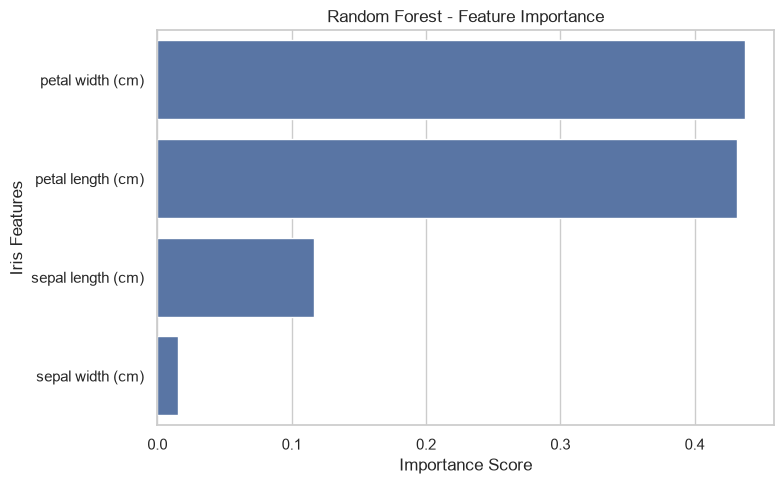

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate feature importance from the Random Forest model
importance = random_forest_model.feature_importances_

# Create a feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

# Display feature importance
display(feature_importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Iris Features")
plt.tight_layout()
plt.show()

## Misclassification Error Analysis

Misclassification analysis examines the samples that a model predicts incorrectly. It helps us understand which Iris species are confused with each other and where the classifier makes mistakes. This analysis can reveal limitations that overall accuracy alone may hide.


In [31]:

import pandas as pd

# Create a DataFrame containing actual and predicted species
error_df = X_test.copy()

error_df["Actual Species"] = [
    iris.target_names[i] for i in y_test
]

error_df["Predicted Species"] = [
    iris.target_names[i] for i in y_pred_random_forest
]

# Filter incorrectly classified samples
misclassified = error_df[
    error_df["Actual Species"] != error_df["Predicted Species"]
]

print("Total test samples:", len(y_test))
print("Misclassified samples:", len(misclassified))

if misclassified.empty:
    print("No misclassifications found for Random Forest.")
else:
    display(misclassified)


Total test samples: 30
Misclassified samples: 3


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual Species,Predicted Species
138,6.0,3.0,4.8,1.8,virginica,versicolor
134,6.1,2.6,5.6,1.4,virginica,versicolor
77,6.7,3.0,5.0,1.7,versicolor,virginica


## Hyperparameter Tuning — K-Nearest Neighbours

Hyperparameter tuning helps identify suitable model settings. For KNN, the `n_neighbors` parameter controls how many nearby training samples are used to classify a flower. We will use 5-fold cross-validation on the training data to select the best value without using the test set for tuning.

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Scale features and tune KNN using training data only
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best parameters:", knn_grid.best_params_)
print(f"Best CV accuracy: {knn_grid.best_score_ * 100:.2f}%")

Best parameters: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}
Best CV accuracy: 96.67%


In [33]:
from sklearn.metrics import accuracy_score, classification_report

best_knn_model = knn_grid.best_estimator_

y_pred_best_knn = best_knn_model.predict(X_test)

print(
    f"Test accuracy: "
    f"{accuracy_score(y_test, y_pred_best_knn) * 100:.2f}%"
)

print(classification_report(
    y_test,
    y_pred_best_knn,
    target_names=iris.target_names
))

Test accuracy: 93.33%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [34]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Final model performance summary
predictions = {
    "Logistic Regression": y_pred_logistic,
    "KNN": y_pred_knn,
    "Decision Tree": y_pred_decision_tree,
    "Random Forest": y_pred_random_forest
}

final_results = []

for model_name, y_pred in predictions.items():
    final_results.append({
        "Model": model_name,
        "Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
        "Precision (%)": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ) * 100,
        "F1-Score (%)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ) * 100
    })

final_results_df = pd.DataFrame(final_results)
final_results_df = final_results_df.sort_values(
    by="F1-Score (%)", ascending=False
).reset_index(drop=True)

display(final_results_df.round(2))

best_model_name = final_results_df.iloc[0]["Model"]
best_accuracy = final_results_df.iloc[0]["Accuracy (%)"]
best_f1 = final_results_df.iloc[0]["F1-Score (%)"]

print("\nFINAL MODEL COMPARISON")
print("----------------------")
print(f"Best model by weighted F1-score: {best_model_name}")
print(f"Test accuracy: {best_accuracy:.2f}%")
print(f"Weighted F1-score: {best_f1:.2f}%")


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,93.33,93.33,93.33,93.33
1,Decision Tree,93.33,93.33,93.33,93.33
2,KNN,93.33,94.44,93.33,93.27
3,Random Forest,90.00,90.24,90.00,89.97



FINAL MODEL COMPARISON
----------------------
Best model by weighted F1-score: Logistic Regression
Test accuracy: 93.33%
Weighted F1-score: 93.33%


## Conclusion

In this project, the Iris Flower Classification dataset was analyzed using exploratory data analysis and data visualization techniques.
Four machine learning classification models were trained and evaluated: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, and Random Forest.
The models were compared using accuracy, confusion matrices, precision, recall, and F1-scores. The best-performing model was selected based on its test accuracy and evaluation results.
The visualizations showed that petal length and petal width are particularly useful features for distinguishing the three Iris species.
This project provided practical experience in data preprocessing, exploratory data analysis, machine learning model training, and performance evaluation.